# Lecture Notes 03: Supplementary Worked Problems and Visual Laboratories: Matrix Algebra, Transformations, and Inverses

**AI 501: Mathematics for Artificial Intelligence**

*Fall 2026*

---

**Abstract.** This document provides a set of rigorous worked problems, geometric proofs, and self-contained interactive Python experiments. The problems cover symmetric/skew-symmetric decompositions, column-space reachability, linear dependence, nullspaces, geometric transformations, determinants as area scalings, and left/right pseudo-inverses. Each problem integrates an analytical walkthrough with executable code designed to help students visualize abstract matrix operations.

---

## Table of Contents
1. Visualizing Matrix Concepts: What to Look For
2. Problem 1: Kinetic Flow and the Symmetric–Skew Decomposition
3. Problem 2: Tall Sensor Networks, Reachability, and Left Pseudo-Inverse
4. Problem 3: Wide Underdetermined Systems and Minimum-Norm Inverses
5. Problem 4: Linear Transformations, Basis Mapping, and Determinants
6. Problem 5: Rank Collapse, Dependent Sensors, and the Nullspace
7. Problem 6: Batch ML Predictions and Parallel Compression

---


## 1. Visualizing Matrix Concepts: What to Look For

Before working through the exercises, consider the geometric interpretation of each core algebraic operation:

1. **Symmetric vs. Skew-Symmetric ($A = S + K$):** $S = \frac{1}{2}(A + A^{\mathsf{T}})$ governs pure strain, expansion, or stretching along orthogonal axes, whereas $K = \frac{1}{2}(A - A^{\mathsf{T}})$ governs pure rigid rotation and circulation without radial expansion ($x^{\mathsf{T}} K x = 0$).
2. **Column Space vs. Nullspace:** The column space $\mathcal{C}(A)$ represents the set of all reachable outputs, whereas the nullspace $\mathcal{N}(A)$ represents directions in the input domain that are squashed to the zero vector, causing information loss.
3. **Matrix Transformations ($y = Ax$):** The columns of $A$ are the destinations of the standard basis vectors $\hat{e}_1, \hat{e}_2, \dots, \hat{e}_n$. The determinant $\det(A)$ is the scaling factor of oriented area or volume. A zero determinant indicates dimension collapse.
4. **Pseudo-Inverses ($A^\dagger$):** For tall matrices, $A^\dagger b = (A^{\mathsf{T}} A)^{-1}A^{\mathsf{T}} b$ projects an unreachable vector orthogonally onto $\mathcal{C}(A)$. For wide matrices, $A^\dagger b = A^{\mathsf{T}}(AA^{\mathsf{T}})^{-1}b$ selects the unique solution on the solution hyperplane closest to the origin ($\min \|x\|_2$).


## 2. Problem 1: Kinetic Flow and the Symmetric--Skew Decomposition

> **Mathematical Core**
>
> Every square matrix decomposes uniquely into symmetric ($S$) and skew-symmetric ($K$) components:
> $$
> A = S + K = \tfrac{1}{2}(A + A^{\mathsf{T}}) + \tfrac{1}{2}(A - A^{\mathsf{T}}).
> $$
> For any vector $x$, the quadratic form isolates $S$: $x^{\mathsf{T}} A x = x^{\mathsf{T}} S x$, since $x^{\mathsf{T}} K x = 0$ identically.

### Problem Statement.

In an urban junction model, local vehicle velocity displacements $[\Delta v_x, \Delta v_y]^{\mathsf{T}}$ around a central roundabout are related to spatial offsets $x = [p_x, p_y]^{\mathsf{T}}$ by the transformation matrix:
$$
A = \begin{pmatrix} 2 & 4 \\ -2 & 2 \end{pmatrix}.
$$

(a) Decompose $A$ into its symmetric component $S$ and skew-symmetric component $K$.

(b) For an arbitrary position vector $x = [x_1, x_2]^{\mathsf{T}}$, calculate the kinetic flux rate $q(x) = x^{\mathsf{T}} A x$. Prove algebraically and verify numerically that $x^{\mathsf{T}} K x = 0$ for all $x$, demonstrating that skew-symmetry contributes zero radial expansion.

(c) Prove that the subspaces of symmetric and skew-symmetric matrices are orthogonal under the Frobenius inner product, and verify that $\|A\|_F^2 = \operatorname{tr}(S^2) - \operatorname{tr}(K^2)$.

### Analytical Solution.

**(a)** We calculate the symmetric and skew-symmetric parts:
$$
S = \frac{A + A^{\mathsf{T}}}{2} = \frac{1}{2} \left[ \begin{pmatrix} 2 & 4 \\ -2 & 2 \end{pmatrix} + \begin{pmatrix} 2 & -2 \\ 4 & 2 \end{pmatrix} \right] = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix},
$$
$$
K = \frac{A - A^{\mathsf{T}}}{2} = \frac{1}{2} \left[ \begin{pmatrix} 2 & 4 \\ -2 & 2 \end{pmatrix} - \begin{pmatrix} 2 & -2 \\ 4 & 2 \end{pmatrix} \right] = \begin{pmatrix} 0 & 3 \\ -3 & 0 \end{pmatrix}.
$$

**(b)** Evaluate the skew-symmetric quadratic form for an arbitrary vector $x$:
$$
x^{\mathsf{T}} K x = \begin{pmatrix} x_1 & x_2 \end{pmatrix} \begin{pmatrix} 0 & 3 \\ -3 & 0 \end{pmatrix} \begin{pmatrix} x_1 \\ x_2 \end{pmatrix} = \begin{pmatrix} x_1 & x_2 \end{pmatrix} \begin{pmatrix} 3x_2 \\ -3x_1 \end{pmatrix} = 3x_1 x_2 - 3x_2 x_1 = 0.
$$
Since $x^{\mathsf{T}} K x = 0$, we have:
$$
x^{\mathsf{T}} A x = x^{\mathsf{T}} (S + K) x = x^{\mathsf{T}} S x = \begin{pmatrix} x_1 & x_2 \end{pmatrix} \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix} \begin{pmatrix} x_1 \\ x_2 \end{pmatrix} = 2x_1^2 + 2x_1 x_2 + 2x_2^2.
$$

**(c)** For any symmetric $S$ and skew-symmetric $K$:
$$
\operatorname{tr}(S^{\mathsf{T}} K) = \operatorname{tr}(SK) = \operatorname{tr}((SK)^{\mathsf{T}}) = \operatorname{tr}(K^{\mathsf{T}} S^{\mathsf{T}}) = \operatorname{tr}(-KS) = -\operatorname{tr}(SK).
$$
Since $\operatorname{tr}(SK) = -\operatorname{tr}(SK)$, it follows that $\operatorname{tr}(S^{\mathsf{T}} K) = 0$, proving orthogonality. Now expanding $A = S + K$:
$$
\|A\|_F^2 = \operatorname{tr}(A^{\mathsf{T}} A) = \operatorname{tr}((S - K)(S + K)) = \operatorname{tr}(S^2) - \operatorname{tr}(K^2) + \operatorname{tr}(SK - KS).
$$
By cyclic invariance of the trace, $\operatorname{tr}(SK) = \operatorname{tr}(KS)$, so:
$$
\|A\|_F^2 = \operatorname{tr}(S^2) - \operatorname{tr}(K^2).
$$
Evaluating the components directly:
$$
\|A\|_F^2 = 2^2 + 4^2 + (-2)^2 + 2^2 = 4 + 16 + 4 + 4 = 28,
$$
$$
S^2 = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}\begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix} = \begin{pmatrix} 5 & 4 \\ 4 & 5 \end{pmatrix} \implies \operatorname{tr}(S^2) = 10,
$$
$$
K^2 = \begin{pmatrix} 0 & 3 \\ -3 & 0 \end{pmatrix}\begin{pmatrix} 0 & 3 \\ -3 & 0 \end{pmatrix} = \begin{pmatrix} -9 & 0 \\ 0 & -9 \end{pmatrix} \implies \operatorname{tr}(K^2) = -18.
$$
Thus, $\operatorname{tr}(S^2) - \operatorname{tr}(K^2) = 10 - (-18) = 28 = \|A\|_F^2$.

### Visual Code Laboratory.


||A||_F^2 = 28.0 | Tr(S^2) - Tr(K^2) = 28.0


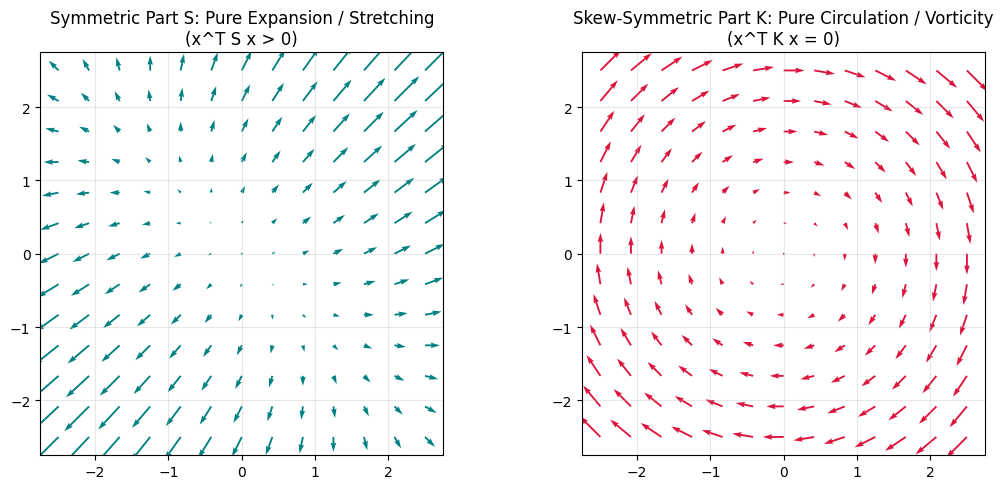

In [1]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[2.0, 4.0],
              [-2.0, 2.0]])

# 1. Decomposition
S = 0.5 * (A + A.T)
K = 0.5 * (A - A.T)

# 2. Trace verification
norm_A_sq = np.sum(A**2)
trace_check = np.trace(S @ S) - np.trace(K @ K)
print(f"||A||_F^2 = {norm_A_sq:.1f} | Tr(S^2) - Tr(K^2) = {trace_check:.1f}")

# 3. Vector Field Visualizer (Expansion vs. Rotation)
grid_x, grid_y = np.meshgrid(np.linspace(-2.5, 2.5, 13), np.linspace(-2.5, 2.5, 13))
pts = np.vstack([grid_x.ravel(), grid_y.ravel()])

flow_S = (S @ pts).reshape(2, 13, 13)
flow_K = (K @ pts).reshape(2, 13, 13)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
ax1.quiver(grid_x, grid_y, flow_S[0], flow_S[1], color="teal")
ax1.set_title("Symmetric Part S: Pure Expansion / Stretching\n(x^T S x > 0)")
ax1.set_aspect("equal")
ax1.grid(True, alpha=0.3)

ax2.quiver(grid_x, grid_y, flow_K[0], flow_K[1], color="crimson")
ax2.set_title("Skew-Symmetric Part K: Pure Circulation / Vorticity\n(x^T K x = 0)")
ax2.set_aspect("equal")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 3. Problem 2: Tall Sensor Networks, Reachability, and Left Pseudo-Inverse

> **Mathematical Core**
>
> When $M \in \mathbb{R}^{m \times n}$ is tall ($m > n$) with full column rank:
> $$
> M^\dagger = (M^{\mathsf{T}} M)^{-1} M^{\mathsf{T}} \implies M^\dagger M = I_n.
> $$
> If $b \notin \mathcal{C}(M)$, $Mx = b$ has no exact solution. The least-squares estimate $x^* = M^\dagger b$ produces a projection $\hat{b} = M x^*$ such that the residual $e = b - \hat{b}$ is strictly orthogonal to $\mathcal{C}(M)$ ($M^{\mathsf{T}} e = \mathbf{0}$).

### Problem Statement.

A traffic control center monitors $m = 3$ approach sensors driven by $n = 2$ green-light control variables:
$$
A = \begin{pmatrix} 1 & 0 \\ 1 & 1 \\ 0 & 1 \end{pmatrix}.
$$

(a) Compute the Gram matrix $G = A^{\mathsf{T}} A$, confirm it is symmetric and non-singular, and determine the left pseudo-inverse $A^\dagger$.

(b) Test whether the target queue reduction $b = (3, 1, 4)^{\mathsf{T}}$ is reachable.

(c) Calculate the optimal least-squares setting $x^* = A^\dagger b$, compute the predicted output $\hat{b} = A x^*$, and prove that the error residual $e = b - \hat{b}$ is perpendicular to every column of $A$.

### Analytical Solution.

**(a)** The Gram matrix of column inner products is:
$$
A^{\mathsf{T}} A = \begin{pmatrix} 1 & 1 & 0 \\ 0 & 1 & 1 \end{pmatrix} \begin{pmatrix} 1 & 0 \\ 1 & 1 \\ 0 & 1 \end{pmatrix} = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}.
$$
$\det(A^{\mathsf{T}} A) = 4 - 1 = 3 \neq 0$, so $A^{\mathsf{T}} A$ is invertible. The left pseudo-inverse is:
$$
(A^{\mathsf{T}} A)^{-1} = \frac{1}{3}\begin{pmatrix} 2 & -1 \\ -1 & 2 \end{pmatrix},
$$
$$
A^\dagger = (A^{\mathsf{T}} A)^{-1} A^{\mathsf{T}} = \frac{1}{3}\begin{pmatrix} 2 & -1 \\ -1 & 2 \end{pmatrix} \begin{pmatrix} 1 & 1 & 0 \\ 0 & 1 & 1 \end{pmatrix} = \frac{1}{3}\begin{pmatrix} 2 & 1 & -1 \\ -1 & 1 & 2 \end{pmatrix}.
$$
Check: $A^\dagger A = \frac{1}{3}\begin{pmatrix} 2 & 1 & -1 \\ -1 & 1 & 2 \end{pmatrix}\begin{pmatrix} 1 & 0 \\ 1 & 1 \\ 0 & 1 \end{pmatrix} = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix} = I_2$.

**(b)** For $b \in \mathcal{C}(A)$, there must exist $x = (x_1, x_2)^{\mathsf{T}}$ such that $x_1 a_1 + x_2 a_2 = b$:
$$
x_1 = 3, \quad x_2 = 4 \implies x_1 + x_2 = 7 \neq 1.
$$
The system is inconsistent; $b$ lies outside the column span $\mathcal{C}(A)$.

**(c)** Compute $x^* = A^\dagger b$:
$$
x^* = \frac{1}{3}\begin{pmatrix} 2 & 1 & -1 \\ -1 & 1 & 2 \end{pmatrix} \begin{pmatrix} 3 \\ 1 \\ 4 \end{pmatrix} = \frac{1}{3}\begin{pmatrix} 2(3) + 1(1) - 1(4) \\ -1(3) + 1(1) + 2(4) \end{pmatrix} = \frac{1}{3}\begin{pmatrix} 3 \\ 6 \end{pmatrix} = \begin{pmatrix} 1 \\ 2 \end{pmatrix}.
$$
The orthogonal projection of $b$ onto the column space is:
$$
\hat{b} = A x^* = \begin{pmatrix} 1 & 0 \\ 1 & 1 \\ 0 & 1 \end{pmatrix}\begin{pmatrix} 1 \\ 2 \end{pmatrix} = \begin{pmatrix} 1 \\ 3 \\ 2 \end{pmatrix}.
$$
The residual error vector is:
$$
e = b - \hat{b} = \begin{pmatrix} 3 \\ 1 \\ 4 \end{pmatrix} - \begin{pmatrix} 1 \\ 3 \\ 2 \end{pmatrix} = \begin{pmatrix} 2 \\ -2 \\ 2 \end{pmatrix}.
$$
Testing orthogonality against the columns of $A$:
$$
A^{\mathsf{T}} e = \begin{pmatrix} 1 & 1 & 0 \\ 0 & 1 & 1 \end{pmatrix} \begin{pmatrix} 2 \\ -2 \\ 2 \end{pmatrix} = \begin{pmatrix} 1(2) + 1(-2) + 0(2) \\ 0(2) + 1(-2) + 1(2) \end{pmatrix} = \begin{pmatrix} 0 \\ 0 \end{pmatrix}.
$$
Because $A^{\mathsf{T}} e = \mathbf{0}$, the error vector is strictly orthogonal to $\mathcal{C}(A)$.

### Visual Code Laboratory.


Optimal x*: [1. 2.]
Projected b_hat: [1. 3. 2.]
Residual e: [ 2. -2.  2.]
A^T @ e (Orthogonality check): [0. 0.]


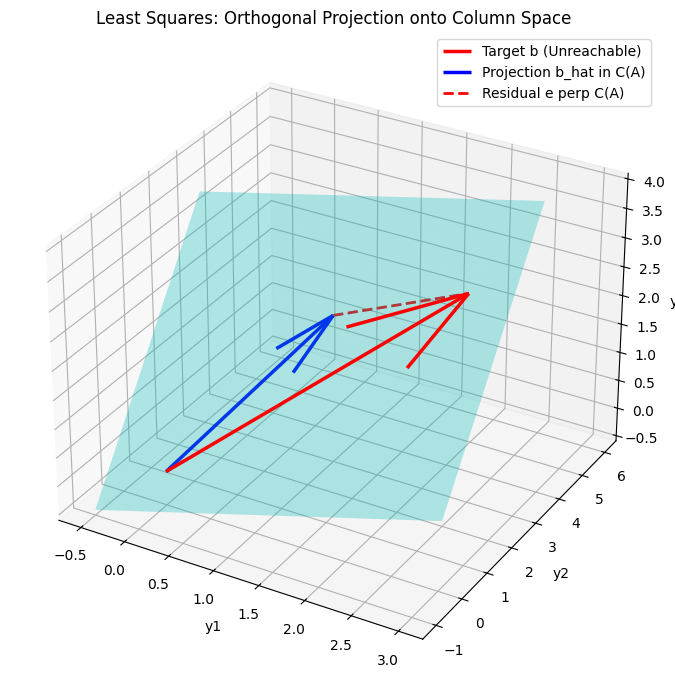

In [2]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[1.0, 0.0],
              [1.0, 1.0],
              [0.0, 1.0]])
b = np.array([3.0, 1.0, 4.0])

# Pseudo-inverse and projection
A_pinv = np.linalg.inv(A.T @ A) @ A.T
x_star = A_pinv @ b
b_hat = A @ x_star
residual = b - b_hat

print(f"Optimal x*: {x_star}")
print(f"Projected b_hat: {b_hat}")
print(f"Residual e: {residual}")
print(f"A^T @ e (Orthogonality check): {A.T @ residual}")

# 3D Visualizer: Column Space Plane vs. Vector b vs. Projected b_hat
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# Generate the 2D column space plane
u, v = np.meshgrid(np.linspace(-0.5, 2.5, 10), np.linspace(-0.5, 3.5, 10))
plane = u[..., None] * A[:, 0] + v[..., None] * A[:, 1]
ax.plot_surface(plane[:, :, 0], plane[:, :, 1], plane[:, :, 2], alpha=0.3, color="cyan")

# Draw vectors
origin = np.zeros(3)
ax.quiver(*origin, *b, color="red", label="Target b (Unreachable)", linewidth=2.5)
ax.quiver(*origin, *b_hat, color="blue", label="Projection b_hat in C(A)", linewidth=2.5)
ax.plot([b_hat[0], b[0]], [b_hat[1], b[1]], [b_hat[2], b[2]], "r--", label="Residual e perp C(A)", linewidth=2)

ax.set_xlabel("y1")
ax.set_ylabel("y2")
ax.set_zlabel("y3")
ax.set_title("Least Squares: Orthogonal Projection onto Column Space")
ax.legend()
plt.tight_layout()
plt.show()


## 4. Problem 3: Wide Underdetermined Systems and Minimum-Norm Inverses

> **Mathematical Core: Underdetermined Systems & Affine Solution Sets**
>
> When $M \in \mathbb{R}^{m \times n}$ is wide ($m < n$) with full row rank, there are fewer equation constraints than unknowns ($m < n$).
>
> **1. The Null Space (Kernel):** The null space $\mathcal{N}(M)$ is defined as the set of all input vectors that $M$ maps to the zero vector:
> $$
> \mathcal{N}(M) = \{v \in \mathbb{R}^n \mid Mv = \mathbf{0}\}.
> $$
> Any vector in the null space represents an internal adjustment or "blind spot" that creates zero net change at the sensor/output level.
>
> **2. General Solution Decomposition ($x = x_p + v$):** If $x_p$ is any *particular solution* satisfying $M x_p = b$, and $v \in \mathcal{N}(M)$ is any null space vector, then their sum is also a valid solution:
> $$
> M(x_p + v) = M x_p + M v = b + \mathbf{0} = b.
> $$
> Because $\mathcal{N}(M)$ contains a continuum of vectors, the solution set forms an *affine subspace* (a shifted line, plane, or hyperplane) with infinitely many valid configurations.
>
> **3. The Minimum-Norm Right Pseudo-Inverse:** Out of this infinite family of solutions, the right pseudo-inverse:
> $$
> M^\dagger = M^{\mathsf{T}} (M M^{\mathsf{T}})^{-1} \implies M M^\dagger = I_m,
> $$
> isolates the unique solution $x^* = M^\dagger b$ that has the smallest Euclidean norm ($\min \|x\|_2$). Geometrically, $x^*$ is perpendicular to the null space shift direction, representing the path of least control effort.

### Problem Statement.

A corridor bottleneck sensor demands a queue reduction of $b = 6$ vehicles/min. We can allocate green time across $n = 2$ coordinated approach phases with sensitivity matrix:
$$
A = \begin{pmatrix} 1 & 2 \end{pmatrix}.
$$

(a) Find the parametric general solution to $Ax = 6$ by expressing $x$ as $x_p + v$, where $v \in \mathcal{N}(A)$.

(b) Calculate the right pseudo-inverse $A^\dagger = A^{\mathsf{T}} (A A^{\mathsf{T}})^{-1}$ and evaluate $x^* = A^\dagger b$.

(c) Prove that $x^*$ has the smallest Euclidean norm among all valid solutions.

### Analytical Solution.

**(a) Deriving the Null Space and General Solution:**
We wish to find all input vectors $x = \begin{pmatrix} x_1 \\ x_2 \end{pmatrix} \in \mathbb{R}^2$ satisfying:
$$
\begin{pmatrix} 1 & 2 \end{pmatrix} \begin{pmatrix} x_1 \\ x_2 \end{pmatrix} = 6 \iff x_1 + 2x_2 = 6.
$$
This is a single linear equation in two unknowns, leaving $2 - 1 = 1$ degree of freedom.

*Step 1: Finding a Particular Solution ($x_p$).* We pick any convenient pair $(x_1, x_2)$ that solves the equation. Setting $x_2 = 0$ immediately yields $x_1 = 6$. Thus:
$$
x_p = \begin{pmatrix} 6 \\ 0 \end{pmatrix} \quad \text{satisfies} \quad A x_p = 1(6) + 2(0) = 6.
$$

*Step 2: Finding the Homogeneous Solution / Null Space ($\mathcal{N}(A)$).* To find all vectors that produce zero output ($Av = \mathbf{0}$):
$$
\begin{pmatrix} 1 & 2 \end{pmatrix} \begin{pmatrix} v_1 \\ v_2 \end{pmatrix} = 0 \iff v_1 + 2v_2 = 0 \implies v_1 = -2v_2.
$$
Treating the free variable $v_2$ as a parameter $t \in \mathbb{R}$, any vector in the null space has the form:
$$
v = \begin{pmatrix} -2t \\ t \end{pmatrix} = t \begin{pmatrix} -2 \\ 1 \end{pmatrix}, \quad t \in \mathbb{R}.
$$
Therefore, the null space $\mathcal{N}(A)$ is a 1-dimensional line through the origin in $\mathbb{R}^2$, spanned by the basis vector $(-2, 1)^{\mathsf{T}}$:
$$
\mathcal{N}(A) = \operatorname{span}\left( \begin{pmatrix} -2 \\ 1 \end{pmatrix} \right).
$$

*Step 3: Assembling the Full Affine Solution Set.* By linearity, adding any multiple of the null space vector $v$ to our particular solution $x_p$ yields another valid solution, because $A(x_p + v) = Ax_p + Av = 6 + 0 = 6$. The complete set of solutions is:
$$
x = x_p + v = \begin{pmatrix} 6 \\ 0 \end{pmatrix} + t \begin{pmatrix} -2 \\ 1 \end{pmatrix}, \quad t \in \mathbb{R}.
$$
Note that this affine solution set is precisely the null space direction $N(A)$, shifted away from the origin by the particular solution $x_p$ --- every point on the line can be reached by starting at $x_p$ and moving along the null space vector $\begin{pmatrix} -2 \\ 1 \end{pmatrix}$ by some amount $t$. Geometrically, this represents a line in $\mathbb{R}^2$ that passes through $(6,0)$ and runs parallel to the null space vector $(-2, 1)^{\mathsf{T}}$.

**(b)** Compute $A A^{\mathsf{T}} = \begin{pmatrix} 1 & 2 \end{pmatrix}\begin{pmatrix} 1 \\ 2 \end{pmatrix} = 1 + 4 = 5$. Then:
$$
A^\dagger = A^{\mathsf{T}} (A A^{\mathsf{T}})^{-1} = \begin{pmatrix} 1 \\ 2 \end{pmatrix} \frac{1}{5} = \begin{pmatrix} 0.2 \\ 0.4 \end{pmatrix}.
$$
Applying $A^\dagger$ to $b = 6$:
$$
x^* = A^\dagger b = \begin{pmatrix} 0.2 \\ 0.4 \end{pmatrix} (6) = \begin{pmatrix} 1.2 \\ 2.4 \end{pmatrix}.
$$
Verification: $Ax^* = 1(1.2) + 2(2.4) = 1.2 + 4.8 = 6$.

**(c)** Any valid solution can be written as $x = x^* + v$, where $v \in \mathcal{N}(A)$ (meaning $Av = \mathbf{0}$). Compute its squared norm:
$$
\|x\|_2^2 = \|x^* + v\|_2^2 = \|x^*\|_2^2 + \|v\|_2^2 + 2 (x^*)^{\mathsf{T}} v.
$$
Since $x^* = A^{\mathsf{T}} c$ for $c = (AA^{\mathsf{T}})^{-1}b$:
$$
(x^*)^{\mathsf{T}} v = (A^{\mathsf{T}} c)^{\mathsf{T}} v = c^{\mathsf{T}} (Av) = c^{\mathsf{T}} (\mathbf{0}) = 0.
$$
Because the cross term vanishes identically:
$$
\|x\|_2^2 = \|x^*\|_2^2 + \|v\|_2^2 \ge \|x^*\|_2^2.
$$
Equality holds if and only if $v = \mathbf{0}$. Therefore, $x^* = (1.2, 2.4)^{\mathsf{T}}$ is uniquely the minimum-norm solution.

### Visual Code Laboratory.


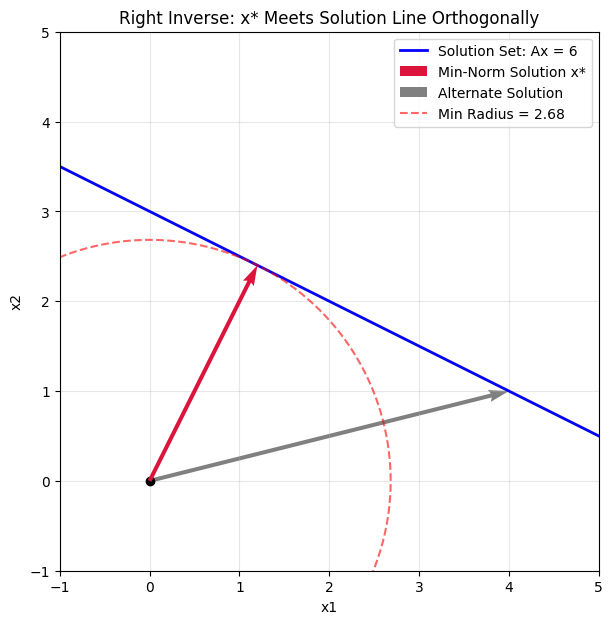

In [3]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[1.0, 2.0]])
b = np.array([6.0])

# Right pseudo-inverse
A_pinv = A.T @ np.linalg.inv(A @ A.T)
x_star = (A_pinv @ b).ravel()

# Solution line: x1 + 2*x2 = 6  =>  x2 = (6 - x1) / 2
x1_vals = np.linspace(-1, 5, 200)
x2_vals = (6.0 - x1_vals) / 2.0

plt.figure(figsize=(7, 7))
plt.plot(x1_vals, x2_vals, "b-", label="Solution Set: Ax = 6", lw=2)

# Plot origin and pseudo-inverse solution
plt.scatter(0, 0, color="black", zorder=5)
plt.quiver(0, 0, x_star[0], x_star[1], angles="xy", scale_units="xy", scale=1,
           color="crimson", label="Min-Norm Solution x*", zorder=6)

# Plot an alternate valid solution
x_alt = np.array([4.0, 1.0])
plt.quiver(0, 0, x_alt[0], x_alt[1], angles="xy", scale_units="xy", scale=1,
           color="gray", label="Alternate Solution")

# Distance circle for min-norm radius
theta = np.linspace(0, 2*np.pi, 200)
r_min = np.linalg.norm(x_star)
plt.plot(r_min * np.cos(theta), r_min * np.sin(theta), "r--", alpha=0.6, label=f"Min Radius = {r_min:.2f}")

plt.xlim(-1, 5)
plt.ylim(-1, 5)
plt.gca().set_aspect("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Right Inverse: x* Meets Solution Line Orthogonally")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.show()


## 5. Problem 4: Linear Transformations, Basis Mapping, and Determinants

> **Mathematical Core**
>
> Under a linear transformation $y = Ax$, the columns of $A$ are the transformed images of the standard basis vectors: $a_1 = A\hat{e}_1$, $a_2 = A\hat{e}_2$. The determinant $\det(A)$ represents the signed area scaling factor. If $\det(A) = 0$, space is compressed into a lower-dimensional subspace, destroying invertibility.

### Problem Statement.

Consider two geometric transformations in $\mathbb{R}^2$:
$$
A = \begin{pmatrix} 1 & 1.5 \\ 0 & 1 \end{pmatrix} \quad (\text{horizontal shear}), \qquad B = \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix} \quad (90^\circ \text{ counter-clockwise rotation}).
$$

(a) Determine where the unit square vertices $[(0,0), (1,0), (1,1), (0,1)]$ land under $A$, $B$, and the composite operation $C = BA$.

(b) Compute $\det(A)$, $\det(B)$, and $\det(C)$. Explain their physical area meanings.

(c) Compute $D = AB$ and demonstrate non-commutativity ($AB \neq BA$).

### Analytical Solution.

**(a)** The transformed basis vectors correspond directly to matrix columns:
$$
A\hat{e}_1 = \begin{pmatrix} 1 \\ 0 \end{pmatrix}, \quad A\hat{e}_2 = \begin{pmatrix} 1.5 \\ 1 \end{pmatrix}, \qquad B\hat{e}_1 = \begin{pmatrix} 0 \\ 1 \end{pmatrix}, \quad B\hat{e}_2 = \begin{pmatrix} -1 \\ 0 \end{pmatrix}.
$$
The composite matrix $C = BA$ is:
$$
C = BA = \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} 1 & 1.5 \\ 0 & 1 \end{pmatrix} = \begin{pmatrix} 0 & -1 \\ 1 & 1.5 \end{pmatrix}.
$$

**(b)** Evaluating the determinants:
$$
\det(A) = (1)(1) - (1.5)(0) = 1, \quad \det(B) = (0)(0) - (-1)(1) = 1,
$$
$$
\det(C) = \det(BA) = \det(B)\det(A) = (1)(1) = 1.
$$
All three transformations preserve the oriented area of the unit square ($\text{Area} = 1.0$), though $A$ and $C$ introduce skew and change angles.

**(c)** Evaluating $D = AB$:
$$
D = AB = \begin{pmatrix} 1 & 1.5 \\ 0 & 1 \end{pmatrix} \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix} = \begin{pmatrix} 1.5 & -1 \\ 1 & 0 \end{pmatrix}.
$$
Since $BA = \begin{pmatrix} 0 & -1 \\ 1 & 1.5 \end{pmatrix} \neq \begin{pmatrix} 1.5 & -1 \\ 1 & 0 \end{pmatrix} = AB$, matrix multiplication is non-commutative. Shearing then rotating produces a different orientation than rotating then shearing.

### Visual Code Laboratory.


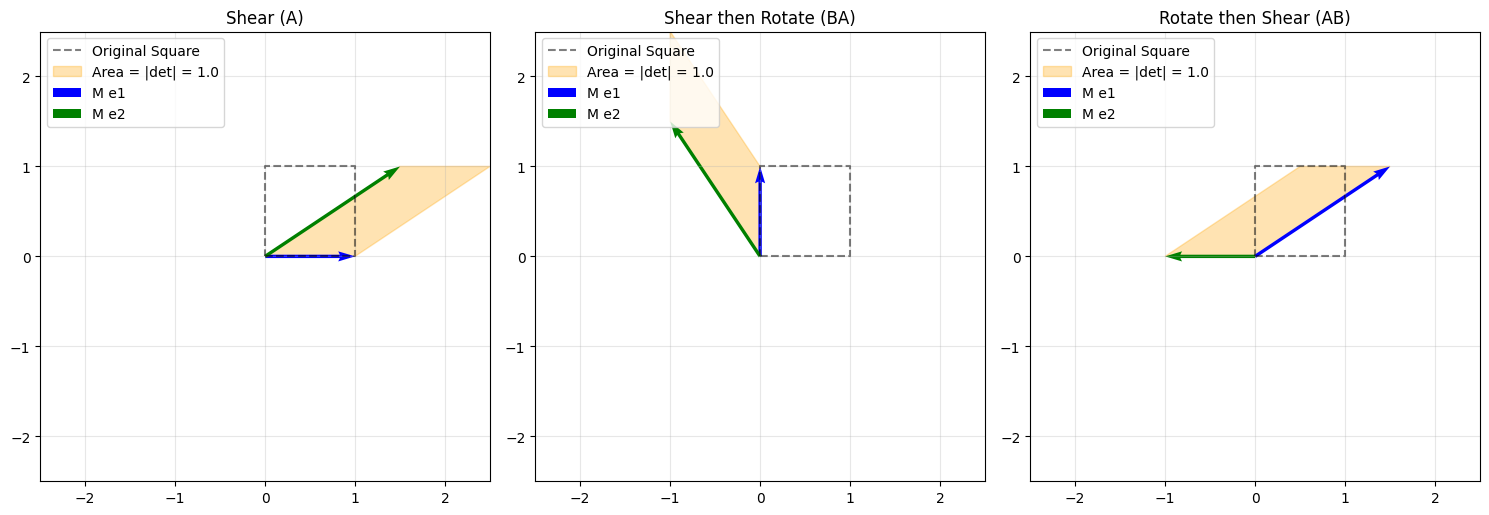

In [4]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[1.0, 1.5], [0.0, 1.0]])       # Shear
B = np.array([[0.0, -1.0], [1.0, 0.0]])      # Rotation
C = B @ A                                     # Shear then Rotate
D = A @ B                                     # Rotate then Shear

square = np.array([[0, 1, 1, 0, 0],
                   [0, 0, 1, 1, 0]])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
titles = ["Shear (A)", "Shear then Rotate (BA)", "Rotate then Shear (AB)"]
transforms = [A, C, D]

for ax, M, title in zip(axes, transforms, titles):
    trans_sq = M @ square
    ax.plot(square[0], square[1], "k--", alpha=0.5, label="Original Square")
    ax.fill(trans_sq[0], trans_sq[1], color="orange", alpha=0.3,
            label=f"Area = |det| = {abs(np.linalg.det(M)):.1f}")
    ax.quiver(0, 0, M[0, 0], M[1, 0], angles="xy", scale_units="xy", scale=1, color="blue", label="M e1")
    ax.quiver(0, 0, M[0, 1], M[1, 1], angles="xy", scale_units="xy", scale=1, color="green", label="M e2")
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    ax.set_title(title)
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()


## 6. Problem 5: Rank Collapse, Dependent Sensors, and the Nullspace

> **Mathematical Core: A Self-Contained Guide to Null Space, Rank, and Dimension Conservation**
>
> To understand why matrices fail to be invertible, we must trace what linear transformations do to the dimensions of input and output spaces.
>
> **1. The Column Space (Reachable Outputs):** For any matrix $M \in \mathbb{R}^{m \times n}$, the column space $\mathcal{C}(M)$ is the set of all vectors that can be produced as linear combinations of $M$'s columns:
> $$
> \mathcal{C}(M) = \{y \in \mathbb{R}^m \mid y = Mx \text{ for some } x \in \mathbb{R}^n\} = \operatorname{span}(m_1, m_2, \dots, m_n).
> $$
> The **Rank** of $M$, written $\operatorname{rank}(M)$, is the dimension of this reachable output space (i.e., the number of linearly independent columns).
>
> **2. The Null Space (Crushed Inputs):** The null space (or kernel) $\mathcal{N}(M)$ consists of all input vectors that are squashed to the zero vector by $M$:
> $$
> \mathcal{N}(M) = \{x \in \mathbb{R}^n \mid Mx = \mathbf{0}\}.
> $$
> The **Nullity** of $M$, written $\operatorname{nullity}(M) = \dim(\mathcal{N}(M))$, is the number of independent input directions collapsed to zero.
>
> **3. The Rank-Nullity Theorem (Conservation of Dimensional Capacity):** Every linear transformation maps an $n$-dimensional input space $\mathbb{R}^n$ into an $m$-dimensional output space $\mathbb{R}^m$. The fundamental theorem of linear algebra states that the input dimensions must be conserved:
> $$
> \boxed{\operatorname{rank}(M) + \operatorname{nullity}(M) = n}
> $$
> $$
> \underbrace{\operatorname{dim}(\mathcal{C}(M))}_{\text{Dimensions preserved in output}} \;+\; \underbrace{\operatorname{dim}(\mathcal{N}(M))}_{\text{Dimensions collapsed to zero}} \;=\; \underbrace{n}_{\text{Total input dimensions}}.
> $$
>
> **4. Why Information Loss Destroys Invertibility:**
> If $\operatorname{nullity}(M) > 0$, there exists at least one non-zero direction $c \in \mathcal{N}(M)$ such that $Mc = \mathbf{0}$. If two distinct inputs $x_1 \neq x_2$ differ by $c$ ($x_2 = x_1 + c$), then:
> $$
> M x_2 = M(x_1 + c) = M x_1 + M c = M x_1 + \mathbf{0} = M x_1.
> $$
> Different inputs produce identical outputs! Once multiple inputs are merged into the same output, no inverse operation $M^{-1}$ can ever deduce which original input created the signal. Thus, a square matrix is invertible **if and only if** its null space contains only the zero vector ($\operatorname{nullity}(M) = 0 \iff \operatorname{rank}(M) = n \iff \det(M) \neq 0$).

### Problem Statement.

A traffic sensor array produces an output response matrix $M \in \mathbb{R}^{3 \times 3}$:
$$
M = \begin{pmatrix} 1 & 2 & 3 \\ 2 & 1 & 3 \\ 3 & 3 & 6 \end{pmatrix}.
$$

(a) Identify the linear dependence among the columns of $M$ and find a non-zero vector $c \in \mathcal{N}(M)$ such that $Mc = \mathbf{0}$.

(b) Determine $\operatorname{rank}(M)$ and $\dim(\mathcal{N}(M))$. Does $M^{-1}$ exist?

(c) Determine whether $y_1 = (6, 6, 12)^{\mathsf{T}}$ and $y_2 = (1, 2, 5)^{\mathsf{T}}$ belong to $\mathcal{C}(M)$.

### Analytical Solution.

**(a)** Notice that column 3 is the sum of columns 1 and 2:
$$
a_3 = a_1 + a_2 \implies 1 \cdot a_1 + 1 \cdot a_2 + (-1) \cdot a_3 = \mathbf{0}.
$$
Thus, $c = (1, 1, -1)^{\mathsf{T}}$ is a non-trivial vector satisfying $Mc = \mathbf{0}$.

**(b)** Columns $a_1 = (1, 2, 3)^{\mathsf{T}}$ and $a_2 = (2, 1, 3)^{\mathsf{T}}$ are not scalar multiples of each other, so they form a linearly independent pair. Since column 3 is a linear combination of $a_1$ and $a_2$, $\operatorname{rank}(M) = 2$.
By the Rank-Nullity Theorem:
$$
\operatorname{nullity}(M) = n - \operatorname{rank}(M) = 3 - 2 = 1.
$$
Because $\operatorname{rank}(M) < 3$, the matrix is singular and $M^{-1}$ does not exist ($\det(M) = 0$).

**(c)** Any output $y \in \mathcal{C}(M)$ must satisfy the linear relation present across the rows:
$$
\text{Row}_3 = \text{Row}_1 + \text{Row}_2 \implies y_3 = y_1 + y_2.
$$
- For $y_1 = (6, 6, 12)^{\mathsf{T}}$: $6 + 6 = 12$. The condition holds. Choosing $x = (1, 1, 1)^{\mathsf{T}}$ yields $Mx = a_1 + a_2 + a_3 = (6, 6, 12)^{\mathsf{T}}$. Thus $y_1 \in \mathcal{C}(M)$.
- For $y_2 = (1, 2, 5)^{\mathsf{T}}$: $1 + 2 = 3 \neq 5$. The condition fails. Therefore $y_2 \notin \mathcal{C}(M)$ and cannot be reached.

### Visual Code Laboratory.


M @ c = [0. 0. 0.] (Collapses to 0)


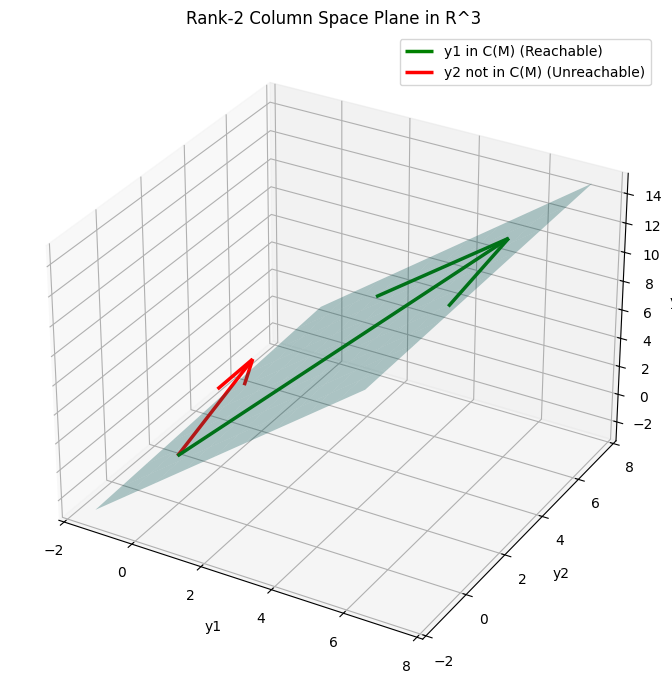

In [5]:
import numpy as np
import matplotlib.pyplot as plt

M = np.array([[1.0, 2.0, 3.0],
              [2.0, 1.0, 3.0],
              [3.0, 3.0, 6.0]])

# Nullspace vector
c = np.array([1.0, 1.0, -1.0])
print(f"M @ c = {M @ c} (Collapses to 0)")

y1 = np.array([6.0, 6.0, 12.0])
y2 = np.array([1.0, 2.0, 5.0])

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# Generate the 2D column space plane
s, t = np.meshgrid(np.linspace(-0.5, 2.5, 10), np.linspace(-0.5, 2.5, 10))
plane = s[..., None] * M[:, 0] + t[..., None] * M[:, 1]
ax.plot_surface(plane[:, :, 0], plane[:, :, 1], plane[:, :, 2], alpha=0.3, color="cyan")

ax.quiver(0, 0, 0, *y1, color="green", linewidth=2.5, label="y1 in C(M) (Reachable)")
ax.quiver(0, 0, 0, *y2, color="red", linewidth=2.5, label="y2 not in C(M) (Unreachable)")

ax.set_xlabel("y1")
ax.set_ylabel("y2")
ax.set_zlabel("y3")
ax.set_title("Rank-2 Column Space Plane in R^3")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Problem 6: Batch ML Predictions and Parallel Compression

> **Mathematical Core**
>
> Matrix multiplication serves dual roles in AI:
> - **Matrix-Vector ($Xw + b\mathbf{1}$):** Evaluates a linear model on all samples simultaneously (Row scoring) or blends features weighted by model parameters (Column blending).
> - **Matrix-Matrix ($AS$):** Projects or compresses multiple observation vectors in parallel.

### Problem Statement.

A traffic control center monitors $m = 3$ intersections across $p = 4$ approaches (North, East, South, West) in matrix $A \in \mathbb{R}^{3 \times 4}$:
$$
A = \begin{pmatrix} 30 & 18 & 25 & 12 \\ 22 & 10 & 15 & 8 \\ 40 & 25 & 30 & 20 \end{pmatrix}.
$$

(a) Using a linear delay model with weights $w = (0.6, 0.3, 0.5, 0.2)^{\mathsf{T}}$ and bias $b = 4$, compute the predicted delays $\hat{y} = Aw + b\mathbf{1}$ via row scoring and verify it via column blending.

(b) Design a compression matrix $S \in \mathbb{R}^{4 \times 2}$ that maps each intersection to two features: Total North–South volume ($A_{\text{N}} + A_{\text{S}}$) and East–West imbalance ($A_{\text{E}} - A_{\text{W}}$).

(c) Compute $Y = AS$ and compare the Frobenius norm $\|A\|_F^2$ with $\|Y\|_F^2$.

### Analytical Solution.

**(a)** Row-scoring computation:
$$
Aw = \begin{pmatrix} 30(0.6) + 18(0.3) + 25(0.5) + 12(0.2) \\ 22(0.6) + 10(0.3) + 15(0.5) + 8(0.2) \\ 40(0.6) + 25(0.3) + 30(0.5) + 20(0.2) \end{pmatrix} = \begin{pmatrix} 18 + 5.4 + 12.5 + 2.4 \\ 13.2 + 3 + 7.5 + 1.6 \\ 24 + 7.5 + 15 + 4 \end{pmatrix} = \begin{pmatrix} 38.3 \\ 25.3 \\ 50.5 \end{pmatrix}.
$$
Adding bias: $\hat{y} = Aw + 4\mathbf{1} = (42.3, 29.3, 54.5)^{\mathsf{T}}$.

Column-blending computation:
$$
0.6 \begin{pmatrix} 30 \\ 22 \\ 40 \end{pmatrix} + 0.3 \begin{pmatrix} 18 \\ 10 \\ 25 \end{pmatrix} + 0.5 \begin{pmatrix} 25 \\ 15 \\ 30 \end{pmatrix} + 0.2 \begin{pmatrix} 12 \\ 8 \\ 20 \end{pmatrix} + \begin{pmatrix} 4 \\ 4 \\ 4 \end{pmatrix} = \begin{pmatrix} 42.3 \\ 29.3 \\ 54.5 \end{pmatrix}.
$$

**(b)** The compression matrix is constructed by columns:
$$
S = \begin{pmatrix} 1 & 0 \\ 0 & 1 \\ 1 & 0 \\ 0 & -1 \end{pmatrix} \in \mathbb{R}^{4 \times 2}.
$$

**(c)** Evaluating $Y = AS$:
$$
Y = \begin{pmatrix} 30 & 18 & 25 & 12 \\ 22 & 10 & 15 & 8 \\ 40 & 25 & 30 & 20 \end{pmatrix} \begin{pmatrix} 1 & 0 \\ 0 & 1 \\ 1 & 0 \\ 0 & -1 \end{pmatrix} = \begin{pmatrix} 30+25 & 18-12 \\ 22+15 & 10-8 \\ 40+30 & 25-20 \end{pmatrix} = \begin{pmatrix} 55 & 6 \\ 37 & 2 \\ 70 & 5 \end{pmatrix}.
$$
Norm comparisons:
$$
\|A\|_F^2 = \operatorname{tr}(AA^{\mathsf{T}}) = 6391,
$$
$$
\|Y\|_F^2 = (55^2 + 6^2) + (37^2 + 2^2) + (70^2 + 5^2) = 3061 + 1373 + 4925 = 9359.
$$
Because $S$ is not an orthonormal matrix ($S^{\mathsf{T}} S \neq I$), it does not preserve the Frobenius norm.

### Visual Code Laboratory.


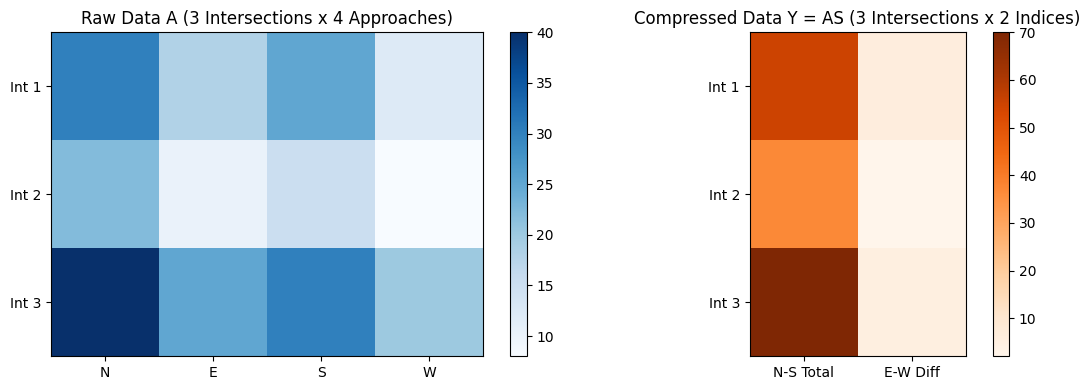

In [6]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[30, 18, 25, 12],
              [22, 10, 15,  8],
              [40, 25, 30, 20]])

S = np.array([[1,  0],
              [0,  1],
              [1,  0],
              [0, -1]])

Y = A @ S

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
im1 = ax1.imshow(A, cmap="Blues")
ax1.set_title("Raw Data A (3 Intersections x 4 Approaches)")
ax1.set_xticks(range(4))
ax1.set_xticklabels(["N", "E", "S", "W"])
ax1.set_yticks(range(3))
ax1.set_yticklabels(["Int 1", "Int 2", "Int 3"])
fig.colorbar(im1, ax=ax1)

im2 = ax2.imshow(Y, cmap="Oranges")
ax2.set_title("Compressed Data Y = AS (3 Intersections x 2 Indices)")
ax2.set_xticks(range(2))
ax2.set_xticklabels(["N-S Total", "E-W Diff"])
ax2.set_yticks(range(3))
ax2.set_yticklabels(["Int 1", "Int 2", "Int 3"])
fig.colorbar(im2, ax=ax2)

plt.tight_layout()
plt.show()
